# 퍼널 분석
- 주문 생성 → 결제 승인 → 배송 시작 → 배송 완료 → 재구매

In [1]:
!pip install matplotlib

In [2]:
!pip install seaborn

In [3]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

conn = sqlite3.connect('../ecommerce.db')
os.makedirs('../output', exist_ok=True)

def query(sql):
    return pd.read_sql(sql, conn)

START_DATE    = '2017-01-01'
END_DATE      = '2018-08-31'
SNAPSHOT_DATE = '2018-09-01'

## 1. 주문 완료율 퍼널

In [4]:
test = query(f"""
    SELECT * FROM orders
""")

display(test)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


In [5]:
# 전체 주문 데이터 가져오기
orders_df = query(f"""
    SELECT * FROM orders
    WHERE order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
""")

# 주문 단계
# 퍼널 분석 대상: 정상 처리된 주문만
# canceled, unavailable 제외
base_df = orders_df[~orders_df['order_status'].isin(['canceled', 'unavailable'])]

order_created    = len(base_df)
payment_approved = base_df['order_approved_at'].notna().sum()
shipped          = base_df['order_delivered_carrier_date'].notna().sum()
delivered        = (base_df['order_status'] == 'delivered').sum()

funnel_data = {
    'Order Created' : order_created,
    'Payment Approved' : payment_approved,
    'Shipped' : shipped,
    'Delivered' : delivered
}

print("📊 주문 퍼널")
for stage, value in funnel_data.items():
    rate = value / order_created * 100
    print(f"{stage:20s}: {value:,}건 ({rate:.1f}%)")

📊 주문 퍼널
Order Created       : 97,910건 (100.0%)
Payment Approved    : 97,891건 (100.0%)
Shipped             : 97,306건 (99.4%)
Delivered           : 96,211건 (98.3%)


[주문 퍼널 분석 결론]
- 전체 주문 완료율 98.3%
- 최대 미완료 구간: 배송시작 → 배송완료 (1,095건, 1.1%)  
 → 배송 분실, 주소 오류 등 배송 품질 이슈 예상

## 2. 퍼널 시각화

              stage  count   rate  drop_off
0     Order Created  97910  100.0         0
1  Payment Approved  97891  100.0        19
2           Shipped  97306   99.4       585
3         Delivered  96211   98.3      1095


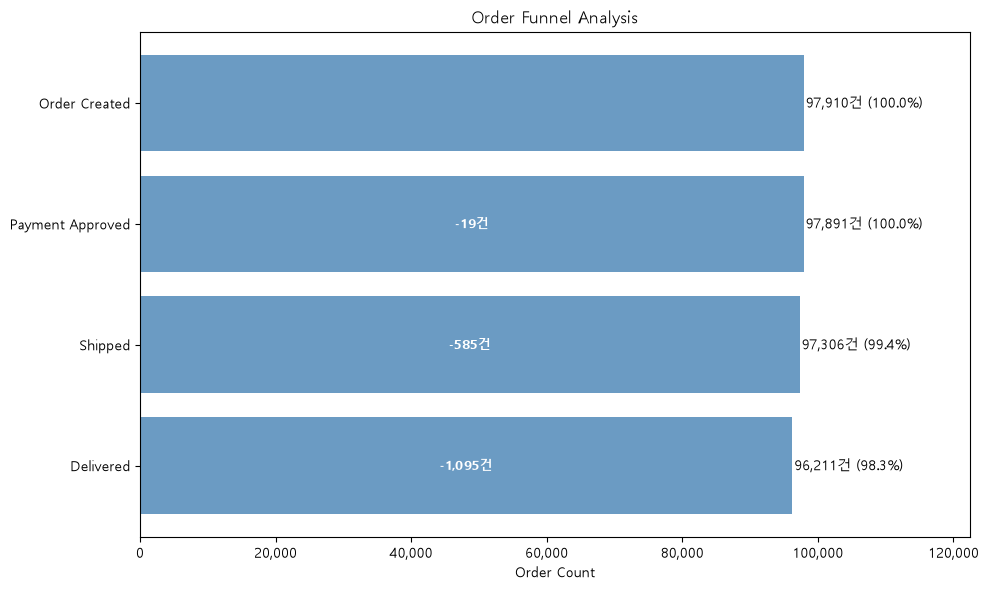

In [6]:
funnel_df = pd.DataFrame({
    'stage' : list(funnel_data.keys()),
    'count' : list(funnel_data.values())
})
funnel_df['rate'] = (funnel_df['count'] / funnel_df['count'][0] * 100).round(1)
funnel_df['drop_off'] = funnel_df['count'].diff().fillna(0).abs().astype(int)

print(funnel_df)

# 시각화
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(funnel_df['stage'][::-1],
               funnel_df['count'][::-1],
               color='steelblue', alpha=0.8)

for bar, (_, row) in zip(bars, funnel_df[::-1].iterrows()):
    # 오른쪽: 건수 + 완료율
    ax.text(bar.get_width() + 300,
            bar.get_y() + bar.get_height() / 2,
            f"{row['count']:,}건 ({row['rate']}%)",
            va='center', fontsize=10)
    # 안쪽: 이탈 수
    if row['drop_off'] > 0:
        ax.text(bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"-{row['drop_off']:,}건",
                va='center', ha='center',
                color='white', fontsize=9, fontweight='bold')

ax.set_title('Order Funnel Analysis')
ax.set_xlabel('Order Count')
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xlim(0, max(funnel_df['count']) * 1.25)
plt.tight_layout()
plt.savefig('../output/order_funnel.png', dpi=150)
plt.show()

## 3. 결제 수단별 완료율

,payment_type,total_orders,delivered_orders,completion_rate
0,boleto,19479,19140,98.3
1,credit_card,75676,74376,98.3
2,debit_card,1514,1484,98.0
3,voucher,5590,5473,97.9


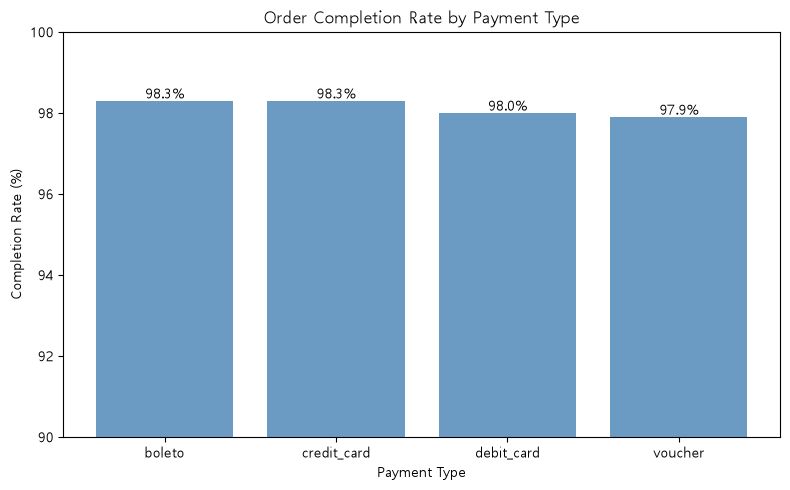

In [7]:
# payments 테이블 가져오기
payments_df = query(f"""
    SELECT order_id, payment_type
    FROM payments
    WHERE order_id IN (
        SELECT order_id FROM orders
        WHERE order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
        )
""")

payment_funnel = (orders_df[~orders_df['order_status'].isin(['canceled', 'unavailable'])]
                    .merge(payments_df, on='order_id')
                    .groupby('payment_type')
                    .agg(
                        total_orders = ('order_id', 'count'),
                        delivered_orders = ('order_status', lambda x: (x == 'delivered').sum())
                    )
                    .reset_index())

payment_funnel['completion_rate'] = (payment_funnel['delivered_orders'] / payment_funnel['total_orders'] * 100).round(1)

payment_funnel = payment_funnel.sort_values('completion_rate', ascending=False)
display(payment_funnel)

# 시각화
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(payment_funnel['payment_type'],
              payment_funnel['completion_rate'],
              color='steelblue', alpha=0.8)
ax.set_ylim(90, 100)
ax.set_title('Order Completion Rate by Payment Type')
ax.set_xlabel('Payment Type')
ax.set_ylabel('Completion Rate (%)')
for bar, rate in zip(bars, payment_funnel['completion_rate']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f'{rate}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../output/payment_completion.png', dpi=150)
plt.show()

[결제 수단별 완료율 결론]
- 모든 결제 수단 완료율 97.9~98.3% → 차이 0.4%p 이내
- 결제 수단은 주문 완료율에 영향 없음

## 4. 배송 소요일 분석

📦 배송 소요일 통계
count    96203.0
mean        12.1
std          9.5
min          0.0
25%          6.0
50%         10.0
75%         15.0
max        209.0
Name: delivery_days, dtype: float64


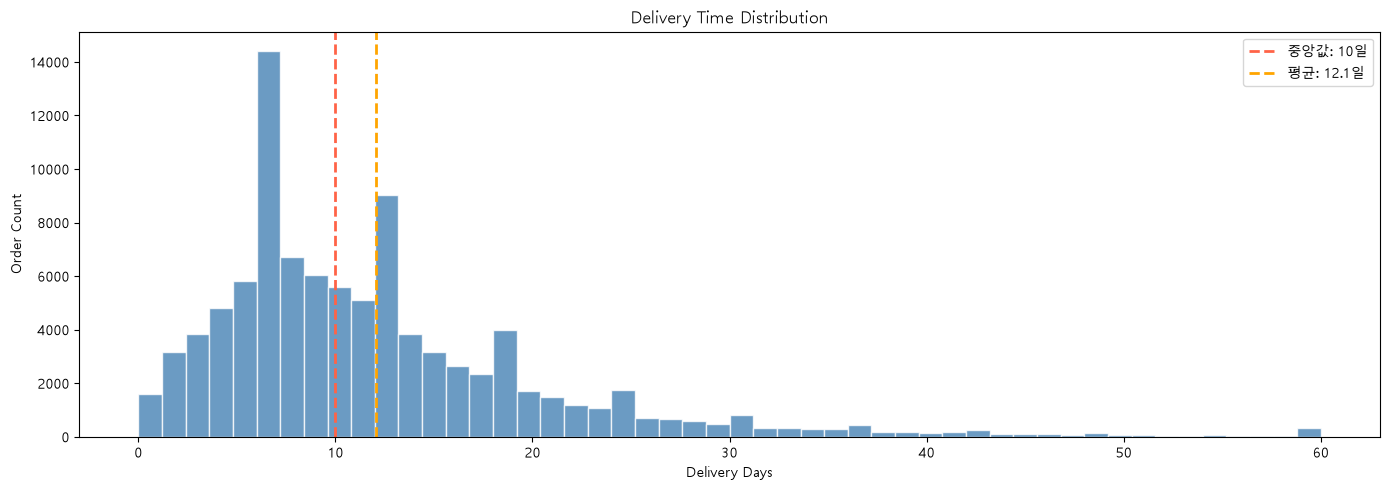

In [8]:
delivery_df = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].notna())
].copy()

# 날짜 컬럼 변환
delivery_df['order_purchase_timestamp'] = pd.to_datetime(
    delivery_df['order_purchase_timestamp'])
delivery_df['order_delivered_customer_date'] = pd.to_datetime(
    delivery_df['order_delivered_customer_date'])

# 배송 소요일 계산
delivery_df['delivery_days'] = (
    delivery_df['order_delivered_customer_date']
    - delivery_df['order_purchase_timestamp']
).dt.days

print("📦 배송 소요일 통계")
print(delivery_df['delivery_days'].describe().round(1))

# 시각화
fig, ax = plt.subplots(figsize=(14, 5))
ax.hist(delivery_df['delivery_days'].clip(upper=60),
        bins=50, color='steelblue', alpha=0.8, edgecolor='white')

median_days = delivery_df['delivery_days'].median()
mean_days   = delivery_df['delivery_days'].mean()

ax.axvline(median_days, color='tomato', linestyle='--', linewidth=2,
           label=f"중앙값: {median_days:.0f}일")
ax.axvline(mean_days, color='orange', linestyle='--', linewidth=2,
           label=f"평균: {mean_days:.1f}일")
ax.set_title('Delivery Time Distribution')
ax.set_xlabel('Delivery Days')
ax.set_ylabel('Order Count')
ax.legend()
plt.tight_layout()
plt.savefig('../output/delivery_time.png', dpi=150)
plt.show()

[배송 소요일 분석 결론]
- 중앙값 10일, 평균 12.1일
- 두 개의 봉우리: 6-7일(근거리), 10-13일(원거리)  
  → 브라질 국토 특성상 지역별 배송 기간 차이 큼
- 25% 고객이 15일 초과 배송 → 장거리 배송 개선 필요
- 최대 209일은 극단적 이상치 → 데이터 품질 이슈 가능성

## 5. 배송 소요일 vs 리뷰 점수

In [9]:
a = query(""" SELECT * FROM reviews """)
display(a)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13


,delivery_days,avg_review_score,order_count
1,1,4.50,1572
2,2,4.48,3161
3,3,4.43,3850
4,4,4.43,4829
5,5,4.39,5800
6,6,4.38,6806
7,7,4.38,7601
8,8,4.35,6740
9,9,4.30,6024
10,10,4.31,5602


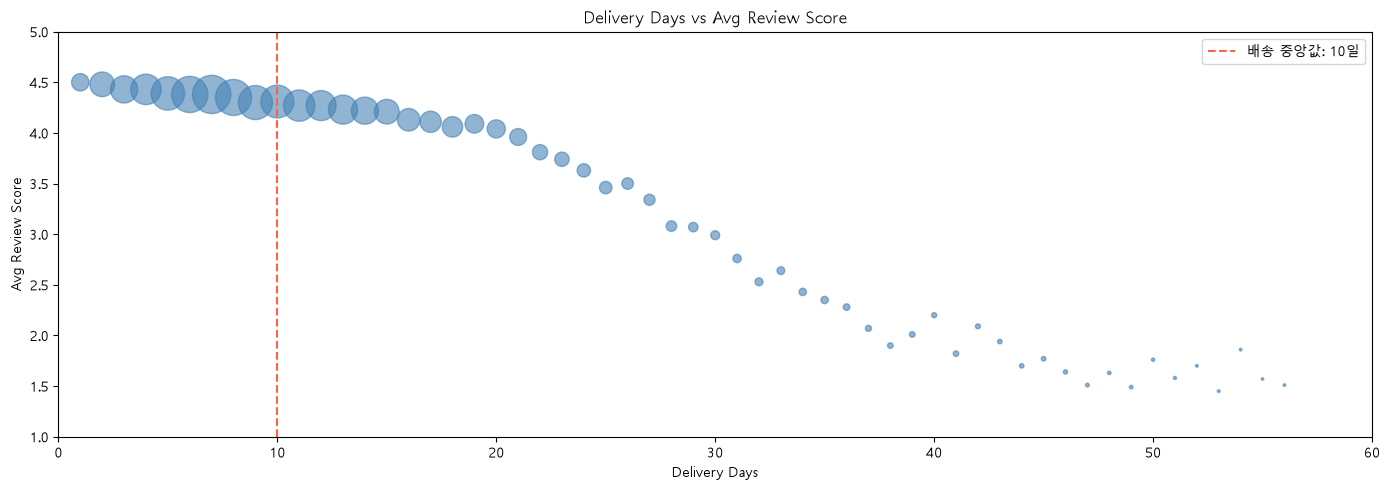

In [10]:
reviews_df = query("""
    SELECT order_id, review_score
    FROM reviews
""")

# delivery랑 merge
delivery_review = (delivery_df
                   .merge(reviews_df, on='order_id')
                   .groupby('delivery_days')
                   .agg(
                       avg_review_score=('review_score', 'mean'),
                       order_count=('order_id', 'count')
                   )
                   .reset_index()
                   .round({'avg_review_score': 2})
                   .query("order_count >= 30"))

display(delivery_review.head(10))

# 시각화
fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(delivery_review['delivery_days'],
           delivery_review['avg_review_score'],
           s=delivery_review['order_count'] / 10,
           color='steelblue', alpha=0.6)
ax.axvline(delivery_df['delivery_days'].median(),
           color='tomato', linestyle='--', linewidth=1.5,
           label=f"배송 중앙값: {delivery_df['delivery_days'].median():.0f}일")
ax.set_title('Delivery Days vs Avg Review Score')
ax.set_xlabel('Delivery Days')
ax.set_ylabel('Avg Review Score')
ax.set_xlim(0, 60)
ax.set_ylim(1, 5)
ax.legend()
plt.tight_layout()
plt.savefig('../output/delivery_vs_review.png', dpi=150)
plt.show()

[배송 소요일 vs 리뷰 점수 결론]
- 배송일이 길어질수록 리뷰 점수 명확하게 하락 (우하향)
- 임계점: 30일 초과 시 리뷰 점수 3점 이하 (불만족)
- 중앙값(10일) 기준 이내: 4.3점 이상 유지
- 분석 2 결과와 연계: 배송 지연 → 불만족 → 이탈 가능성

In [11]:
# 배송 지연 여부 분류 (중앙값 10일 기준)
delivery_df['is_delayed'] = delivery_df['delivery_days'] > 10

delayed_review = (delivery_df
                  .merge(reviews_df, on='order_id')
                  .groupby('is_delayed')['review_score']
                  .agg(['mean', 'count'])
                  .round(2))

delayed_review.index = ['정상 배송 (10일 이내)', '지연 배송 (10일 초과)']
print(delayed_review)

                mean  count
정상 배송 (10일 이내)  4.38  51998
지연 배송 (10일 초과)  3.89  44089


- 주문 완료율 98.3%, 결제 수단별 차이 없음 → 운영/결제 안정적
- 전체 주문의 45.8%가 10일 초과 배송 (지연)
- 지연 배송 리뷰 3.89점 vs 정상 배송 4.38점 → 0.49점 차이
- 30일 초과 시 리뷰 3점 이하로 급락 → 30일을 배송 SLA 기준으로 제안
- 배송 속도 개선이 고객 만족도 향상의 핵심 과제

## 6. 리뷰 감성 분석

In [12]:
!pip install transformers torch

   ---------------------------------------- 0.0/12.3 MB ? eta -:--:--
   ----------------- ---------------------- 5.5/12.3 MB 27.9 MB/s eta 0:00:01
   -------------------------------------- - 11.8/12.3 MB 30.8 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 MB/s eta 0:00:01
   ---------------------------------------  12.1/12.3 MB 29.0 

1. 모델 로드

In [38]:
# 다국어 감성 분석 모델 로드
# nlptown/bert-base-multilingual-uncased-sentiment
# → 6개 언어 지원 (영어, 독일어, 프랑스어, 스페인어, 이탈리아어, 네덜란드어)
# → 포르투갈어와 스페인어가 유사해서 어느 정도 작동함
# → 1~5점 별점 예측 모델
from transformers import pipeline
import torch

sentiment_model = pipeline(
    "text-classification",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    device=0 if torch.cuda.is_available() else -1 # # GPU 있으면 GPU, 없으면 CPU
)

print(f"✅ 모델 로드 완료")
print(f"   GPU 사용: {torch.cuda.is_available()}")

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

✅ 모델 로드 완료
   GPU 사용: False


2. 리뷰 샘플링

In [39]:
reviews_text = query("""
    SELECT
        review_id,
        order_id,
        review_score,
        review_comment_title,
        review_comment_message
    FROM reviews
    WHERE review_comment_message IS NOT NULL
      AND LENGTH(review_comment_message) > 10
""")

print(f"텍스트 리뷰 수: {len(reviews_text):,}건")
display(reviews_text.head(3))

텍스트 리뷰 수: 37,437건


,review_id,order_id,review_score,review_comment_title,review_comment_message
0,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.
1,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...
2,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo,aparelho eficiente. no site a marca do aparelh...


In [40]:
# 점수별 갯수
cnt = reviews_text.groupby('review_score')[
    'review_id'].count()
cnt

review_score
1     8628
2     2104
3     3319
4     5289
5    18097
Name: review_id, dtype: int64

3. 감성 분석 실행

In [59]:
print("전체 리뷰 감성 분석 중...")

all_texts = reviews_text['review_comment_message'].apply(preprocess_text).tolist()
all_results = []
batch_size = 32

for i in range(0, len(all_texts), batch_size):
    batch = all_texts[i:i + batch_size]
    batch_results = sentiment_model(batch, truncation=True, max_length=512)
    all_results.extend(batch_results)

    if (i // batch_size) % 10 == 0:
        progress = min(i + batch_size, len(all_texts))
        pct = progress / len(all_texts) * 100
        print(f"  진행중: {progress:,}/{len(all_texts):,}건 ({pct:.1f}%)")

print(f"\n✅ 완료! 총 {len(all_results):,}건")

# 결과 저장
reviews_text['sentiment']       = [r['label'] for r in all_results]
reviews_text['sentiment_score'] = [r['score'] for r in all_results]
reviews_text['sentiment']       = reviews_text['sentiment'].str.capitalize()

전체 리뷰 감성 분석 중...
  진행중: 32/37,437건 (0.1%)
  진행중: 352/37,437건 (0.9%)
  진행중: 672/37,437건 (1.8%)
  진행중: 992/37,437건 (2.6%)
  진행중: 1,312/37,437건 (3.5%)
  진행중: 1,632/37,437건 (4.4%)
  진행중: 1,952/37,437건 (5.2%)
  진행중: 2,272/37,437건 (6.1%)
  진행중: 2,592/37,437건 (6.9%)
  진행중: 2,912/37,437건 (7.8%)
  진행중: 3,232/37,437건 (8.6%)
  진행중: 3,552/37,437건 (9.5%)
  진행중: 3,872/37,437건 (10.3%)
  진행중: 4,192/37,437건 (11.2%)
  진행중: 4,512/37,437건 (12.1%)
  진행중: 4,832/37,437건 (12.9%)
  진행중: 5,152/37,437건 (13.8%)
  진행중: 5,472/37,437건 (14.6%)
  진행중: 5,792/37,437건 (15.5%)
  진행중: 6,112/37,437건 (16.3%)
  진행중: 6,432/37,437건 (17.2%)
  진행중: 6,752/37,437건 (18.0%)
  진행중: 7,072/37,437건 (18.9%)
  진행중: 7,392/37,437건 (19.7%)
  진행중: 7,712/37,437건 (20.6%)
  진행중: 8,032/37,437건 (21.5%)
  진행중: 8,352/37,437건 (22.3%)
  진행중: 8,672/37,437건 (23.2%)
  진행중: 8,992/37,437건 (24.0%)
  진행중: 9,312/37,437건 (24.9%)
  진행중: 9,632/37,437건 (25.7%)
  진행중: 9,952/37,437건 (26.6%)
  진행중: 10,272/37,437건 (27.4%)
  진행중: 10,592/37,437건 (28.3%)
  진행중: 10,912/37

4. 결과 정리

In [60]:
print("📊 전체 리뷰 감성 분포")
print(reviews_text['sentiment'].value_counts())
display(reviews_text[['review_score', 'review_comment_message',
                       'sentiment', 'sentiment_score']].head(10))

📊 전체 리뷰 감성 분포
sentiment
Positive    21474
Negative    13327
Neutral      2636
Name: count, dtype: int64


,review_score,review_comment_message,sentiment,sentiment_score
0,5,Recebi bem antes do prazo estipulado.,Positive,0.403878
1,5,Parabéns lojas lannister adorei comprar pela I...,Positive,0.836081
2,4,aparelho eficiente. no site a marca do aparelh...,Positive,0.561806
3,4,"Mas um pouco ,travando...pelo valor ta Boa.\r\n",Positive,0.790071
4,5,"Vendedor confiável, produto ok e entrega antes...",Positive,0.931529
5,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...",Positive,0.554770
6,5,Loja nota 10,Positive,0.533052
7,5,obrigado pela atençao amim dispensada,Negative,0.585010
8,5,A compra foi realizada facilmente.\r\nA entreg...,Positive,0.767940
9,5,relógio muito bonito e barato.,Positive,0.986379


[전체 리뷰 감성 분석]
- 전체 37,437건 분석 (텍스트 있는 리뷰만)
- Positive 57.5%, Negative 35.7%, Neutral 7.1%
- 텍스트-점수 불일치 케이스 존재

5. 모델 검증

In [46]:
!pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   -------------------- ------------------- 4.2/8.3 MB 27.9 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 27.9 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.3 MB 14.0 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 12.8 MB/s  0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ----- ---------------------------------- 4.7/36.7 MB 23.8 MB/s eta 0:00:02
   ---------- ----------------------------- 9.2/36.7 MB 22.0 MB/s eta 0:00:02
   --------------- ------------------------ 14.2/36.7 MB 23.4 MB/s eta 0:00:01
   --------------------- ------------------ 19.7/36.7 MB 23.9 MB/s eta 0:00:01
   ---------------------------- ----------- 26.5/36.7 MB 25.8 MB/s eta 0:00:01
   ------------------------------------ --- 33.6/36.7 MB 27.3 MB/s eta 0:00:01
   ---------------------------------------  36.4/36.7 MB 27.9 MB/s eta 0:00:01
   --

In [61]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

def classify_actual(score):
    if score >= 4:
        return 'Positive'
    elif score == 3:
        return 'Neutral'
    else:
        return 'Negative'

reviews_text['actual_sentiment'] = reviews_text['review_score'].apply(classify_actual)

# 3클래스 정확도
accuracy = (reviews_text['sentiment'] == reviews_text['actual_sentiment']).mean()
print(f"📊 3클래스 정확도: {accuracy*100:.1f}%")
print(classification_report(reviews_text['actual_sentiment'],
                             reviews_text['sentiment']))

# 2클래스 정확도
binary = reviews_text[reviews_text['actual_sentiment'] != 'Neutral'].copy()
binary_accuracy = (binary['sentiment'] == binary['actual_sentiment']).mean()
print(f"\n📊 2클래스 정확도: {binary_accuracy*100:.1f}%")
print(classification_report(binary['actual_sentiment'],
                             binary['sentiment']))

📊 3클래스 정확도: 65.7%
              precision    recall  f1-score   support

    Negative       0.49      0.61      0.54     10732
     Neutral       0.13      0.10      0.12      3319
    Positive       0.83      0.76      0.79     23386

    accuracy                           0.66     37437
   macro avg       0.48      0.49      0.48     37437
weighted avg       0.67      0.66      0.66     37437


📊 2클래스 정확도: 71.1%
              precision    recall  f1-score   support

    Negative       0.56      0.61      0.58     10732
     Neutral       0.00      0.00      0.00         0
    Positive       0.88      0.76      0.81     23386

    accuracy                           0.71     34118
   macro avg       0.48      0.46      0.47     34118
weighted avg       0.78      0.71      0.74     34118



- Positive : 83% precision, 76% recall  ← 잘 맞춤
- Negative : 49% precision, 61% recall  ← 보통
- Neutral  : 13% precision, 10% recall  ← 약함

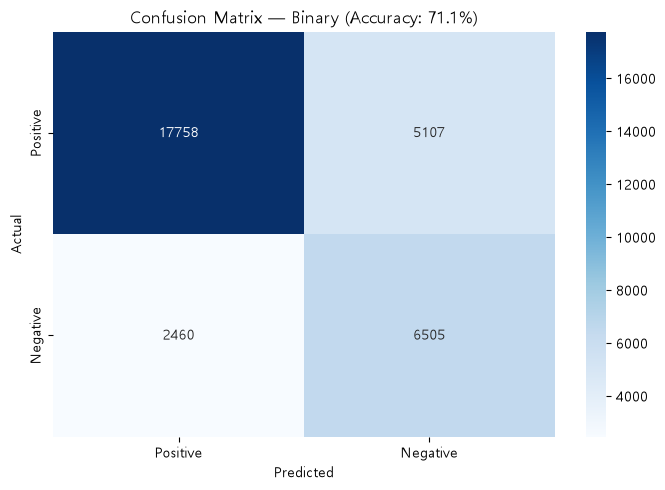

In [62]:
# 혼동 행렬
fig, ax = plt.subplots(figsize=(7, 5))
cm = confusion_matrix(binary['actual_sentiment'],
                      binary['sentiment'],
                      labels=['Positive', 'Negative'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Positive', 'Negative'],
            yticklabels=['Positive', 'Negative'])
ax.set_title(f'Confusion Matrix — Binary (Accuracy: {binary_accuracy*100:.1f}%)')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('../output/sentiment_confusion_full.png', dpi=150)
plt.show()

[전체 리뷰 모델 검증 결론]
- 전체(37,437건)
    - 3클래스: 65.7%
    - 2클래스: 71.1%
  
- 클래스별 성능
    - Positive precision 83% → 긍정 판별 양호
    - Negative precision 49% → 부정 판별 개선 필요
    - Neutral 약함 (13%)

- 실무 활용 시
    - Negative 오분류(27.4%) 주의 → 불만 고객 대응 누락 가능
    - Positive 위주로 신뢰하고 Negative는 보조 지표로 활용 권장

6. 카테고리별 감성 분포

In [65]:
category_col = query(f"""
    SELECT
        r.order_id,
        COALESCE(t.product_category_name_english, p.product_category_name, 'Unknown') AS category
    FROM reviews r
    JOIN orders o USING (order_id)
    JOIN order_items oi USING (order_id)
    JOIN products p USING (product_id)
    LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
""")

reviews_with_category = reviews_text.merge(category_col, on='order_id', how='left')

# 카테고리별 감성 집계
category_text_sentiment = (reviews_with_category
                           .groupby('category')
                           .agg(
                               total = ('sentiment', 'count'),
                               positive = ('sentiment', lambda x: (x=='Positive').sum()),
                               negative = ('sentiment', lambda x: (x=='Negative').sum()),
                               neutral = ('sentiment', lambda x: (x=='Neutral').sum())
                           )
                           .reset_index())

for sentiment in ['positive', 'negative', 'neutral']:
    category_text_sentiment[f'{sentiment}_pct'] = (
        category_text_sentiment[sentiment]
        / category_text_sentiment['total'] * 100
    ).round(1)

# 표본 50건 이상만
category_text_sentiment = (category_text_sentiment
                            [category_text_sentiment['total'] >= 50]
                            .sort_values('positive_pct', ascending=False)
                            .reset_index(drop=True))

print("📊 카테고리별 텍스트 감성 분석")
print(f"분석 카테고리 수: {len(category_text_sentiment)}개")
display(category_text_sentiment.head(10))
display(category_text_sentiment.tail(10))

📊 카테고리별 텍스트 감성 분석
분석 카테고리 수: 52개


,category,total,positive,negative,neutral,positive_pct,negative_pct,neutral_pct
0,fashion_underwear_beach,50,36,13,1,72.0,26.0,2.0
1,books_technical,75,53,20,2,70.7,26.7,2.7
2,computers,79,55,22,2,69.6,27.8,2.5
3,fashion_shoes,121,81,32,8,66.9,26.4,6.6
4,books_general_interest,146,96,43,7,65.8,29.5,4.8
5,luggage_accessories,410,264,134,12,64.4,32.7,2.9
6,fashion_bags_accessories,755,482,228,45,63.8,30.2,6.0
7,musical_instruments,240,151,75,14,62.9,31.2,5.8
8,food_drink,78,49,22,7,62.8,28.2,9.0
9,food,166,104,51,11,62.7,30.7,6.6


,category,total,positive,negative,neutral,positive_pct,negative_pct,neutral_pct
42,fashion_male_clothing,61,32,28,1,52.5,45.9,1.6
43,computers_accessories,2962,1544,1189,229,52.1,40.1,7.7
44,construction_tools_safety,71,37,32,2,52.1,45.1,2.8
45,home_confort,224,114,97,13,50.9,43.3,5.8
46,office_furniture,778,389,336,53,50.0,43.2,6.8
47,home_appliances_2,86,43,37,6,50.0,43.0,7.0
48,fixed_telephony,119,58,56,5,48.7,47.1,4.2
49,signaling_and_security,81,39,40,2,48.1,49.4,2.5
50,kitchen_dining_laundry_garden_furniture,109,51,50,8,46.8,45.9,7.3
51,audio,150,70,66,14,46.7,44.0,9.3


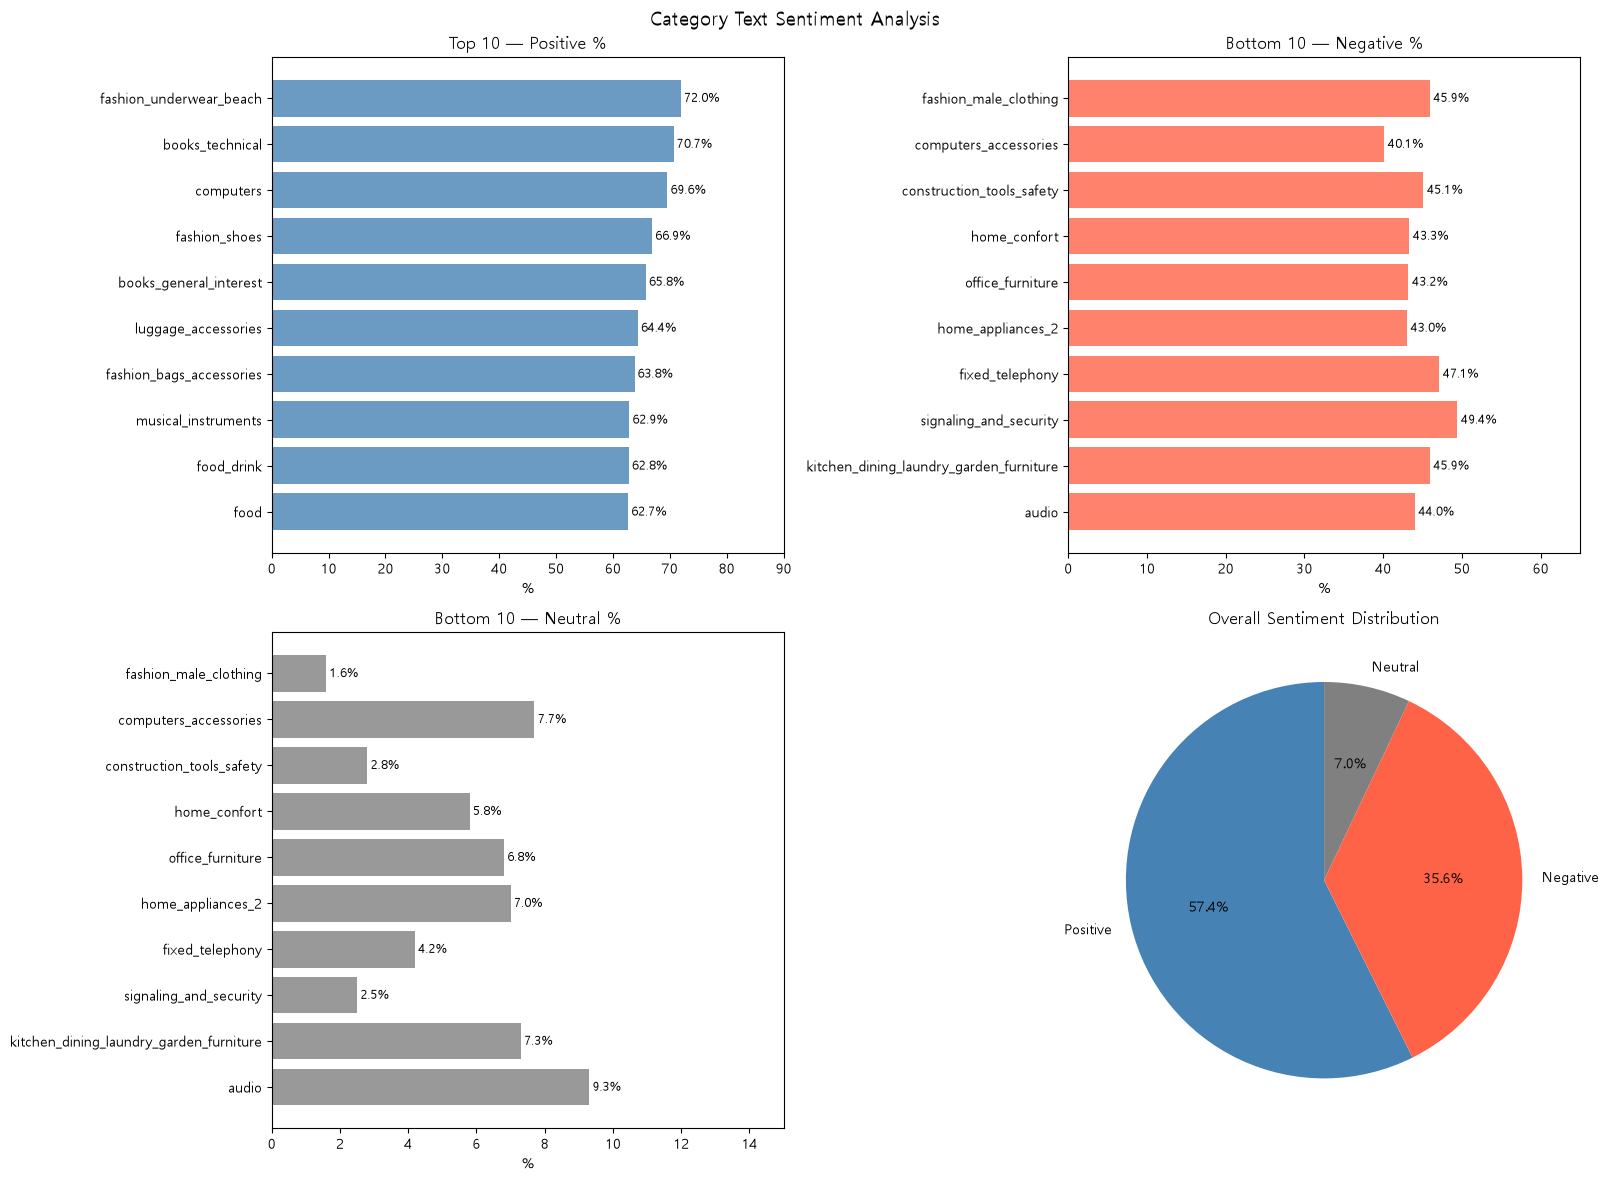

In [68]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

top10    = category_text_sentiment.head(10)
bottom10 = category_text_sentiment.tail(10)

# ① Positive Top 10
axes[0][0].barh(top10['category'][::-1],
                top10['positive_pct'][::-1],
                color='steelblue', alpha=0.8)
axes[0][0].set_title('Top 10 — Positive %')
axes[0][0].set_xlabel('%')
axes[0][0].set_xlim(0, 90)
for i, (_, row) in enumerate(top10[::-1].iterrows()):
    axes[0][0].text(row['positive_pct'] + 0.5, i,
                    f"{row['positive_pct']}%", va='center', fontsize=9)

# ② Negative Top 10
axes[0][1].barh(bottom10['category'][::-1],
                bottom10['negative_pct'][::-1],
                color='tomato', alpha=0.8)
axes[0][1].set_title('Bottom 10 — Negative %')
axes[0][1].set_xlabel('%')
axes[0][1].set_xlim(0, 65)
for i, (_, row) in enumerate(bottom10[::-1].iterrows()):
    axes[0][1].text(row['negative_pct'] + 0.5, i,
                    f"{row['negative_pct']}%", va='center', fontsize=9)

# ③ Neutral Top 10
axes[1][0].barh(bottom10['category'][::-1],
                bottom10['neutral_pct'][::-1],
                color='gray', alpha=0.8)
axes[1][0].set_title('Bottom 10 — Neutral %')
axes[1][0].set_xlabel('%')
axes[1][0].set_xlim(0, 15)
for i, (_, row) in enumerate(bottom10[::-1].iterrows()):
    axes[1][0].text(row['neutral_pct'] + 0.1, i,
                    f"{row['neutral_pct']}%", va='center', fontsize=9)

# ④ 전체 감성 분포 파이차트
sentiment_counts = reviews_text['sentiment'].value_counts()
colors = ['steelblue', 'tomato', 'gray']
axes[1][1].pie(sentiment_counts,
               labels=sentiment_counts.index,
               autopct='%1.1f%%',
               colors=colors,
               startangle=90)
axes[1][1].set_title('Overall Sentiment Distribution')

plt.suptitle('Category Text Sentiment Analysis', fontsize=14)
plt.tight_layout()
plt.savefig('../output/category_text_sentiment.png', dpi=150)
plt.show()

[카테고리별 텍스트 감성 분석 결론]
- 전체 37,437건 기반, 52개 카테고리 분석 (표본 50건 이상)
- Positive 상위: 패션소품, 책, 컴퓨터  
   → 기대치 명확, 소형, 파손 위험 낮음
- Negative 상위: 보안장비, 유선전화, 대형가구  
   → 설치/조립 필요, 기대치와 실물 차이 큼
- 전체 감성: Positive 57.4%, Negative 35.6%, Neutral 7.0%

7. 워드클라우드

In [69]:
!pip install wordcloud nltk

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 16.3 MB/s  0:00:00

   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ----------------------------

In [72]:
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords

# 포르투갈어 불용어 다운로드
nltk.download('stopwords')
portuguese_stopwords = stopwords.words('portuguese')

# 추가 불용어 (이커머스 특성상 의미없는 단어)
extra_stopwords = [
    'produto', 'compra', 'loja', 'recebi',
    'entrega', 'prazo', 'chegou', 'veio',
    'tudo',    # 모든 것
    'ainda',   # 아직도 (너무 일반적)
    'pois',    # 왜냐하면
    'outro',   # 다른
    'apenas',  # 단지
    'apena',   # apenas 오타
]
all_stopwords = portuguese_stopwords + extra_stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\926174\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [73]:
extra_stopwords = [
    'produto', 'compra', 'loja', 'recebi',
    'entrega', 'prazo', 'chegou', 'veio',
    'tudo',    # 모든 것
    'ainda',   # 아직도 (너무 일반적)
    'pois',    # 왜냐하면
    'outro',   # 다른
    'apenas',  # 단지
    'apena',   # apenas 오타
]
all_stopwords = portuguese_stopwords + extra_stopwords

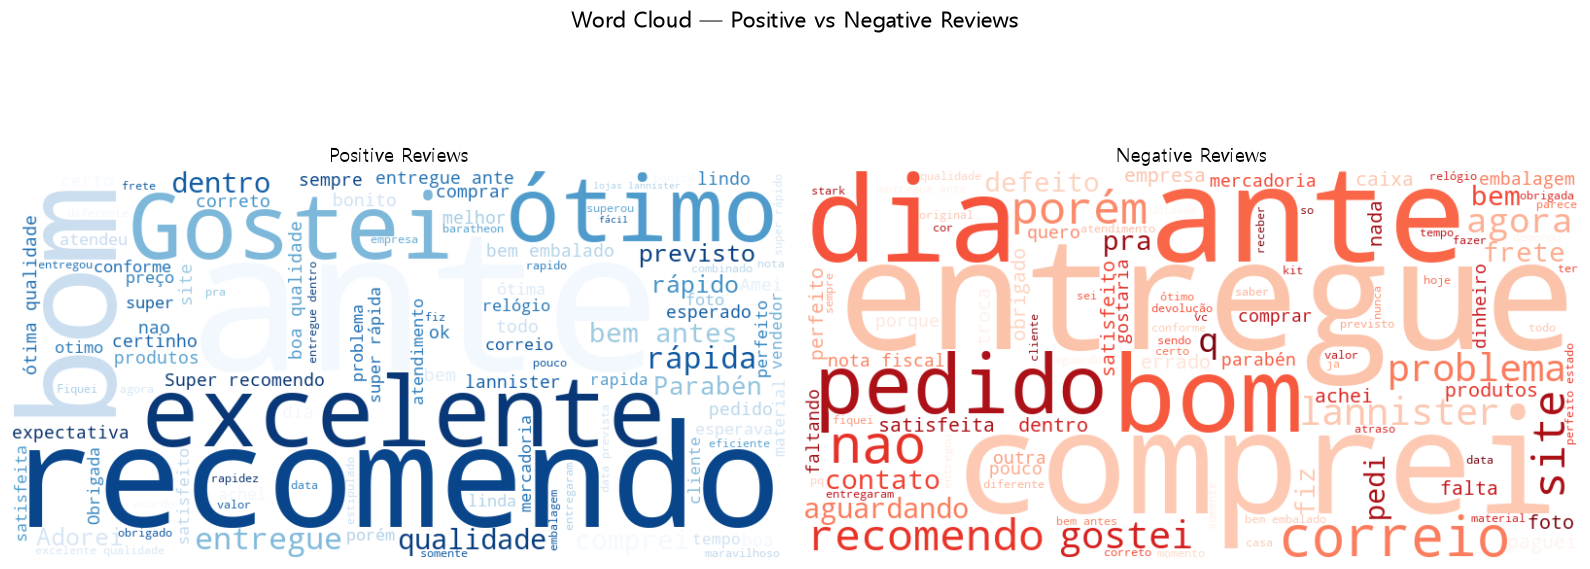

In [74]:
# 긍정/부정 리뷰 텍스트 분리
positive_text = ' '.join(
    reviews_text[reviews_text['sentiment'] == 'Positive']
    ['review_comment_message'].dropna()
)
negative_text = ' '.join(
    reviews_text[reviews_text['sentiment'] == 'Negative']
    ['review_comment_message'].dropna()
)

# 워드클라우드 생성
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, text, title, color in zip(
    axes,
    [positive_text, negative_text],
    ['Positive Reviews', 'Negative Reviews'],
    ['Blues', 'Reds']
):
    wc = WordCloud(
        width=800, height=400,
        background_color='white',
        stopwords=set(all_stopwords),
        colormap=color,
        max_words=100
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=14)

plt.suptitle('Word Cloud — Positive vs Negative Reviews', fontsize=16)
plt.tight_layout()
plt.savefig('../output/wordcloud.png', dpi=150)
plt.show()

[워드클라우드 결론]
-  Positive 핵심:  
 → recomendo, excelente, ótimo → 강한 긍정 표현  
 → entregue + dentro + previsto → 정시/빠른 배송

- Negative 핵심:  
 → dia + entregue + pedido → 배송 지연 (며칠째 안 옴)  
 → correio → 배송사(우체국) 불만  
 → defeito → 결함 상품  
 → site → 플랫폼 불만

- 특이사항:  
 → Negative 리뷰에도 긍정 단어 등장  
 → 복합 감성 텍스트가 많음 → 모델 한계와 연결